In [2]:
import numpy as np
from scipy import stats
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [5]:
# Loading the data
path = "/FrictionFactorData.xlsx"
path = Path(path)
df = pd.read_excel(path, header=[0,1])

In [6]:
# Building the structure with merged header columns for Run Number

lvl0 = pd.Index(df.columns.get_level_values(0)).to_series()
lvl0 = lvl0.replace(r"^Unnamed.*", pd.NA, regex=True).ffill().to_numpy()

lvl1 = df.columns.get_level_values(1)
df.columns = pd.MultiIndex.from_arrays([lvl0, lvl1], names=["Run", "Var"])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [7]:
# Removing empty values

df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

In [8]:
df = df.apply(pd.to_numeric, errors="coerce")

df.head()

Run  Run 1            Run 2          Run 3            Run 4        
Var     Re       f       Re       f     Re       f       Re       f
0     6478  0.0355  19476.0  0.0268  20701  0.0251  11529.0  0.0308
1    11785  0.0303  13439.0  0.0293  13248  0.0286   9993.0  0.0318
2     5485  0.0369  15844.0  0.0281  18409  0.0266   9340.0  0.0329
3     9075  0.0321   5251.0  0.0369   5602  0.0351   3187.0  0.0420
4    11815  0.0302  11980.0  0.0303  14251  0.0281   6248.0  0.0362

In [9]:
# List of Runs
runs = df.columns.get_level_values("Run").unique()

In [10]:
run = "Run 1"  # <-- optional "Run 2", "Run 3", "Run 4"

# Defining arrays with values
Re = df[(run, "Re")].to_numpy(dtype=float)
f  = df[(run, "f")].to_numpy(dtype=float)

In [11]:
# Counting number of valid entries in arrays
# If there are such, statistics can be calculated
n_Re = np.count_nonzero(~np.isnan(Re))
n_f  = np.count_nonzero(~np.isnan(f))

In [12]:
# Calculating mean
Re_mean = np.nanmean(Re) if n_Re > 0 else np.nan
f_mean  = np.nanmean(f)  if n_f  > 0 else np.nan

In [13]:
# Calculating standart deviation
# For degree of freedom = 1, at least 2 valid values are required
Re_std = np.nanstd(Re, ddof=1) if n_Re > 1 else np.nan
f_std  = np.nanstd(f,  ddof=1) if n_f  > 1 else np.nan

In [14]:
# Calculating variance
# # For degree of freedom = 1, at least 2 valid values are required
Re_var = np.nanvar(Re, ddof=1) if n_Re > 1 else np.nan
f_var  = np.nanvar(f,  ddof=1) if n_f  > 1 else np.nan


In [15]:
# Calculating median
Re_med = np.nanmedian(Re) if n_Re > 0 else np.nan
f_med  = np.nanmedian(f)  if n_f  > 0 else np.nan

For skewness, there is no direct equivalent of the MATLAB function `skewness(x)` with NumPy.
The solution to this would be to compute the skewness directly from the data.

First, any missing observations are removed so that the skewness is computed only from valid data. Let the remaining sample be denoted by $(x_1,\dots,x_n)$, where $(n)$ is the number of non-missing values. The sample mean is

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^n x_i.
$$

Define the deviations from the mean by $(d_i = x_i-\bar{x})$. Using these deviations, the second and third *central* moments (computed with division by $(n)$) are

$$
m_2=\frac{1}{n}\sum_{i=1}^n (x_i-\bar{x})^2,
\qquad
m_3=\frac{1}{n}\sum_{i=1}^n (x_i-\bar{x})^3.
$$

The biased (moment-based) skewness is then given by

$$
g_1=\frac{m_3}{m_2^{3/2}}.
$$


MATLAB by default does not [apply a bias correction](https://www.mathworks.com/help/stats/skewness.html).


If $(n<3)$, the correction factor is not defined, and if $(m_2=0)$ (all observations are identical), the skewness is undefined because the denominator becomes zero.
To match the biased MATLAB definition shown in the formula above, the skewness is calculated without bias correction while omitting missing values.



In [16]:
def skewness_numpy(x):
    """
    MATLAB-like skewness(x) (default)
    NaNs are omitted.
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = x.size
    if n == 0:
        return np.nan

    m = x.mean()
    d = x - m

    m2 = np.mean(d**2)
    if m2 == 0:
        return np.nan

    m3 = np.mean(d**3)
    return m3 / (m2 ** 1.5)

In [17]:
Re_skew_np = skewness_numpy(Re)
f_skew_np  = skewness_numpy(f)

Alternatively, a scipy.stats module `skew` can be used directly. The thing to consider is the `bias` flag of the module. Like MATLAB, [the default state](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.skew.html#scipy.stats.skew) of the flag is `True`, so that bias correction is not applied.

In [18]:
# Skewness with scipy module
Re_skew = stats.skew(Re, nan_policy="omit")
f_skew  = stats.skew(f, nan_policy="omit")

In [19]:
# Computing median absolute deviation
Re_mad = np.nanmedian(np.abs(Re - Re_med)) if n_Re > 0 else np.nan
f_mad  = np.nanmedian(np.abs(f  - f_med))  if n_f  > 0 else np.nan

In [20]:
# Creating and printing an output

struct = {
    "run": run,
    "n": {"Re": n_Re, "f": n_f},
    "mean": {"Re": Re_mean, "f": f_mean},
    "std": {"Re": Re_std, "f": f_std},
    "var": {"Re": Re_var, "f": f_var},
    "median": {"Re": Re_med, "f": f_med},
    "skew_np": {"Re": Re_skew_np, "f": f_skew_np},
    "skew": {"Re": Re_skew, "f": f_skew},
    "mad": {"Re": Re_mad, "f": f_mad},
}

print(f"\n=== {run} ===")
print(f"n:    Re={n_Re}, f={n_f}")
print(f"mean: Re={Re_mean:.4e}, f={f_mean:.4e}")
print(f"std:  Re={Re_std:.4e},  f={f_std:.4e}")
print(f"var:  Re={Re_var:.4e},  f={f_var:.4e}")
print(f"med: Re={Re_med:.4e}, f={f_med:.4e}")
print(f"skew_np: Re={Re_skew_np:.4e}, f={f_skew_np:.4e}")
print(f"skew: Re={Re_skew:.4e}, f={f_skew:.4e}")
print(f"mad: Re={Re_mad:.4e}, f={f_mad:.4e}")


=== Run 1 ===
n:    Re=16, f=16
mean: Re=9.7006e+03, f=3.2031e-02
std:  Re=2.2538e+03,  f=2.1325e-03
var:  Re=5.0794e+06,  f=4.5476e-06
med: Re=9.7040e+03, f=3.1650e-02
skew_np: Re=-2.0639e-01, f=8.4379e-01
skew: Re=-2.0639e-01, f=8.4379e-01
mad: Re=1.9255e+03, f=1.2500e-03


The pipeline that has been described so far can be collected into a function for easier usability.

In [21]:
def compute_run_stats(df, run):
    """
    Compute descriptive statistics for a single experiment (run) stored in a MultiIndex DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame with MultiIndex columns (Run, Var). Must contain (run, "Re") and (run, "f").
    run : str
        Run label (e.g., "Run 1", "Run 2", ...), matching the first level of the MultiIndex columns.

    Returns
    -------
    dict
        A dictionary with the computed statistics, structured as:
        {
            "run": run,
            "n": {"Re": ..., "f": ...},
            "mean": {"Re": ..., "f": ...},
            ...
        }
    """
    Re = df[(run, "Re")].to_numpy(dtype=float)
    f  = df[(run, "f")].to_numpy(dtype=float)

    n_Re = np.count_nonzero(~np.isnan(Re))
    n_f  = np.count_nonzero(~np.isnan(f))

    Re_mean = np.nanmean(Re) if n_Re > 0 else np.nan
    f_mean  = np.nanmean(f)  if n_f  > 0 else np.nan

    Re_std = np.nanstd(Re, ddof=1) if n_Re > 1 else np.nan
    f_std  = np.nanstd(f,  ddof=1) if n_f  > 1 else np.nan

    Re_var = np.nanvar(Re, ddof=1) if n_Re > 1 else np.nan
    f_var  = np.nanvar(f,  ddof=1) if n_f  > 1 else np.nan

    Re_med = np.nanmedian(Re) if n_Re > 0 else np.nan
    f_med  = np.nanmedian(f)  if n_f  > 0 else np.nan

    Re_skew_np = skewness_numpy(Re)
    f_skew_np  = skewness_numpy(f)

    Re_ok = Re[~np.isnan(Re)]
    f_ok  = f[~np.isnan(f)]
    Re_skew = stats.skew(Re_ok, bias=True) if Re_ok.size > 0 else np.nan
    f_skew  = stats.skew(f_ok,  bias=True) if f_ok.size  > 0 else np.nan

    Re_mad = np.nanmedian(np.abs(Re - Re_med)) if n_Re > 0 else np.nan
    f_mad  = np.nanmedian(np.abs(f  - f_med))  if n_f  > 0 else np.nan

    struct = {
        "run": run,
        "n": {"Re": n_Re, "f": n_f},
        "mean": {"Re": Re_mean, "f": f_mean},
        "std": {"Re": Re_std, "f": f_std},
        "var": {"Re": Re_var, "f": f_var},
        "median": {"Re": Re_med, "f": f_med},
        "skew_np": {"Re": Re_skew_np, "f": f_skew_np},
        "skew": {"Re": Re_skew, "f": f_skew},
        "mad": {"Re": Re_mad, "f": f_mad},
    }

    print(f"\n=== {run} ===")
    print(f"n:    Re={n_Re}, f={n_f}")
    print(f"mean: Re={Re_mean:.4e}, f={f_mean:.4e}")
    print(f"std:  Re={Re_std:.4e},  f={f_std:.4e}")
    print(f"var:  Re={Re_var:.4e},  f={f_var:.4e}")
    print(f"med:  Re={Re_med:.4e}, f={f_med:.4e}")
    print(f"skew_np: Re={Re_skew_np:.4e}, f={f_skew_np:.4e}")
    print(f"skew: Re={Re_skew:.4e}, f={f_skew:.4e}")
    print(f"mad:  Re={Re_mad:.4e}, f={f_mad:.4e}")

    return struct


In [22]:
run = "Run 1"
stats_struct = compute_run_stats(df, run)


=== Run 1 ===
n:    Re=16, f=16
mean: Re=9.7006e+03, f=3.2031e-02
std:  Re=2.2538e+03,  f=2.1325e-03
var:  Re=5.0794e+06,  f=4.5476e-06
med:  Re=9.7040e+03, f=3.1650e-02
skew_np: Re=-2.0639e-01, f=8.4379e-01
skew: Re=-2.0639e-01, f=8.4379e-01
mad:  Re=1.9255e+03, f=1.2500e-03


In [23]:
run = "Run 4"
stats_struct = compute_run_stats(df, run)


=== Run 4 ===
n:    Re=12, f=12
mean: Re=7.2610e+03, f=3.5700e-02
std:  Re=2.9494e+03,  f=3.8648e-03
var:  Re=8.6987e+06,  f=1.4936e-05
med:  Re=6.6945e+03, f=3.5650e-02
skew_np: Re=1.2464e-01, f=2.0380e-01
skew: Re=1.2464e-01, f=2.0380e-01
mad:  Re=2.7075e+03, f=3.4000e-03


The data set can be visualised with the following steps:

- `plt.figure()` creates a new figure (a fresh plotting canvas),
- a plotting command (e.g., `plt.boxplot(...)` or `plt.plot(...)`) adds data to the current figure,
- `plt.xlabel(...)`, `plt.ylabel(...)`, and `plt.title(...)` add annotations for readability,
- `plt.show()` renders the figure in the notebook output.

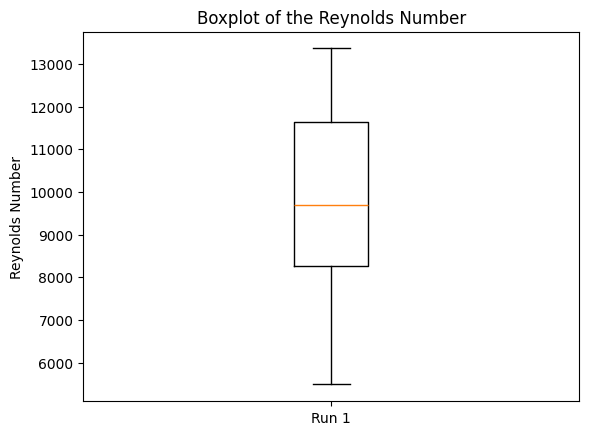

In [24]:
run = "Run 1"  # <-- optional "Run 2", "Run 3", "Run 4"

Re = df[(run, "Re")].to_numpy(dtype=float)
Re = Re[~np.isnan(Re)]

plt.figure()
plt.boxplot(Re, tick_labels=[run])
plt.ylabel("Reynolds Number")
plt.title("Boxplot of the Reynolds Number")
plt.show()

Before creating a scatterplot, the data needs to be prepared so that each plotted point represents a valid pair (Re, f).

Both the Reynolds number array `Re` and the friction factor array `f` may contain missing entries (`NaN`).  
A scatterplot requires paired observations. For every point we plot, both co-ordinates must be real numbers. If either `Re[i]` or `f[i]` is missing, then the pair (Re[i], f[i]) cannot be plotted.

For this reason, a Boolean mask that selects only indices where both variables are present is built:

- `~np.isnan(Re)` marks valid Reynolds numbers,
- `~np.isnan(f)` marks valid friction factors,
- combining them with `&` keeps only rows where both are valid.

Applying this mask produces the filtered arrays `Re_m` and `f_m` which have the same length and contain only complete (Re, f) pairs suitable for plotting.


In [25]:
run = "Run 1"  # <-- optional "Run 2", "Run 3", "Run 4"

Re = df[(run, "Re")].to_numpy(dtype=float)
f  = df[(run, "f")].to_numpy(dtype=float)

mask = ~np.isnan(Re) & ~np.isnan(f)
Re_m, f_m = Re[mask], f[mask]

 `plt.plot(Re, f, 'ob', markerfacecolor='none')`  
  plots the data points.  
  The format string `'ob'` specifies circle markers (`'o'`) in blue (`'b'`).  
  Setting `markerfacecolor='none'` makes the circles hollow, which matches the “open circle” style often used in MATLAB.

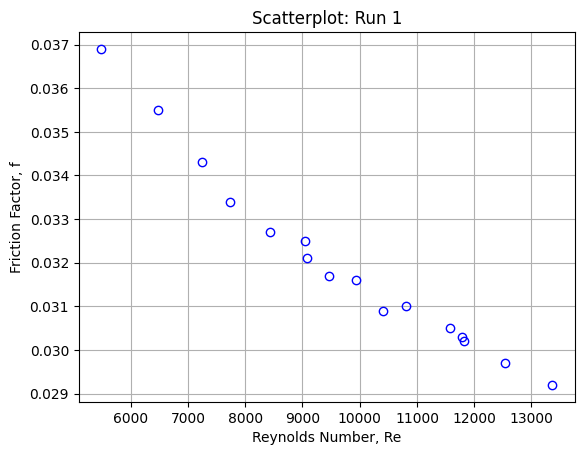

In [26]:
plt.figure()
plt.plot(Re, f, 'ob', markerfacecolor='none')  # blue open circles
plt.xlabel("Reynolds Number, Re")
plt.ylabel("Friction Factor, f")
plt.title(f"Scatterplot: {run}")
plt.grid(True)
plt.show()

In [27]:
# Theoretical curve (vectors)
Re_th = np.arange(5000, 14000 + 1, 100)
f_th  = 0.316 * Re_th**(-0.25)

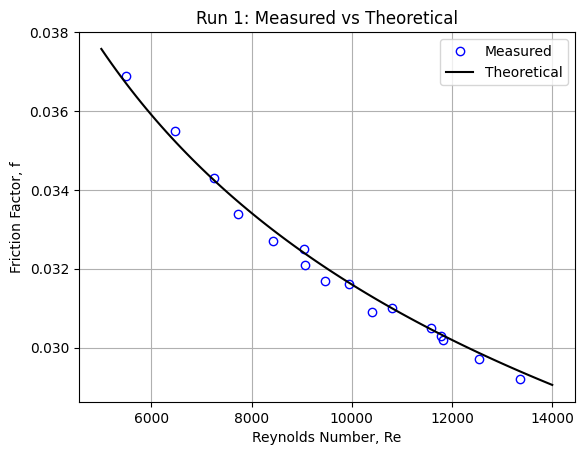

In [28]:
# Plotting together
plt.figure()
plt.plot(Re_m, f_m, 'ob', markerfacecolor='none', label='Measured')  # blue open circles
plt.plot(Re_th, f_th, '-k', label='Theoretical')                    # black line

plt.xlabel("Reynolds Number, Re")
plt.ylabel("Friction Factor, f")
plt.title(f"{run}: Measured vs Theoretical")
plt.grid(True)
plt.legend()
plt.show()